In [1]:
# using IJulia
# installkernel(
#     "Julia FishIns 8 Threads",
#     "--project=/Users/johnbuckner/github/FisheriesInsuranceModel",
#     env = Dict("JULIA_NUM_THREADS" => "8"),
# )

In [2]:
using Pkg
Pkg.activate("../.")
using ValueFunctionIterations
using LaTeXStrings
Pkg.status("ValueFunctionIterations")
include("analysis/bankruptcy.jl")

  Activating project at `~/github/FisheriesInsuranceModel`


Status `~/github/FisheriesInsuranceModel/Project.toml`
  [dc40bd75] ValueFunctionIterations v0.7.7 `https://github.com/Jack-H-Buckner/ValueFunctionIterations.jl.git#master`


print_bankruptcy (generic function with 1 method)

In [ ]:
b_rate_100 = bankruptcy_rate("no_RA_int_pr100_re100", N = 100)
print("done 1")
b_rate_75 = bankruptcy_rate("no_RA_int_pr75_re75", N = 100)
print("done 2")
b_rate_60 = bankruptcy_rate("no_RA_int_pr60_re60", N = 100)
print("done 3")
b_rate_50 = bankruptcy_rate("no_RA_int_pr50_re50", N = 100)
print("done 4")

In [5]:
b_rate_100_cv33 = bankruptcy_rate("no_RA_int_pr100_re100_cv33", N = 100)
print("done 1")
b_rate_75_cv33 = bankruptcy_rate("no_RA_int_pr75_re75_cv33", N = 100)
print("done 2")
b_rate_60_cv33 = bankruptcy_rate("no_RA_int_pr60_re60_cv33", N = 100)
print("done 3")
b_rate_50_cv33 = bankruptcy_rate("no_RA_int_pr50_re50_cv33", N = 100)
print("done 4")

simulating 100 paired trajectories of 250 periods on 8 threads (common random numbers)
events (insurance / none): 53 / 95 out of 100   exposure 19182 / 8438 periods
P10        = 0.0273 (0.0213, 0.034)
P10_no_I   = 0.1065 (0.0897, 0.1277)
reduction  = 0.0792 (0.0624, 0.0993)
λ ratio    = 0.2454 (0.1845, 0.3165)
done 1simulating 100 paired trajectories of 250 periods on 8 threads (common random numbers)
events (insurance / none): 76 / 95 out of 100   exposure 14487 / 8438 periods
P10        = 0.0511 (0.0419, 0.0619)
P10_no_I   = 0.1065 (0.0897, 0.1277)
reduction  = 0.0554 (0.0401, 0.0732)
λ ratio    = 0.466 (0.3769, 0.5673)
done 2simulating 100 paired trajectories of 250 periods on 8 threads (common random numbers)
events (insurance / none): 88 / 95 out of 100   exposure 10864 / 8438 periods
P10        = 0.0778 (0.0642, 0.094)
P10_no_I   = 0.1065 (0.0897, 0.1277)
reduction  = 0.0287 (0.0141, 0.045)
λ ratio    = 0.7195 (0.6044, 0.8504)
done 3simulating 100 paired trajectories of 250 perio

In [6]:
using DataFrames, CSV

rows = [
    merge((scenario = "pr100_re100",      pr = 1.00, cv = 0.00), b_rate_100),
    merge((scenario = "pr75_re75",        pr = 0.75, cv = 0.00), b_rate_75),
    merge((scenario = "pr60_re60",        pr = 0.60, cv = 0.00), b_rate_60),
    merge((scenario = "pr50_re50",        pr = 0.50, cv = 0.00), b_rate_50),
    merge((scenario = "pr100_re100_cv33", pr = 1.00, cv = 0.33), b_rate_100_cv33),
    merge((scenario = "pr75_re75_cv33",   pr = 0.75, cv = 0.33), b_rate_75_cv33),
    merge((scenario = "pr60_re60_cv33",   pr = 0.60, cv = 0.33), b_rate_60_cv33),
    merge((scenario = "pr50_re50_cv33",   pr = 0.50, cv = 0.33), b_rate_50_cv33),
]

df = DataFrame(rows)
CSV.write("figures/bankruptcy_iso_premium.csv", df)
df


Row,scenario,pr,cv,N,n_events,n_events_no_I,exposure,exposure_no_I,lambda,lambda_lo,lambda_hi,lambda_no_I,lambda_no_I_lo,lambda_no_I_hi,lambda_ratio,ratio_lo,ratio_hi,horizon,P10,P10_lo,P10_hi,P10_no_I,P10_no_I_lo,P10_no_I_hi,P10_reduction,P10_reduction_lo,P10_reduction_hi,frac_bankrupt,frac_bankrupt_no_I,boot_dropped,B,T,seed,paired,common_draws,s0_savings,minutes
,String,Float64,Float64,Int64,Int64,Int64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Int64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Int64,Int64,Int64,Int64,Bool,Bool,Float64,Float64
1,pr100_re100,1.0,0.0,100,26,95,22119.0,8438.0,0.00117546,0.000775862,0.00163165,0.0112586,0.00939299,0.013658,0.104406,0.0659381,0.149149,10,0.0116858,0.0077286,0.0161841,0.106479,0.0896534,0.127663,0.0947936,0.0777701,0.115631,0.26,0.95,0,2000,250,123,true,true,0.0,4.9956
2,pr75_re75,0.75,0.0,100,66,95,16215.0,8438.0,0.00407031,0.00321813,0.00507865,0.0112586,0.00939299,0.013658,0.361529,0.288431,0.449462,10,0.0398858,0.0316689,0.0495184,0.106479,0.0896534,0.127663,0.0665936,0.051196,0.0848918,0.66,0.95,0,2000,250,123,true,true,0.0,4.94338
3,pr60_re60,0.6,0.0,100,81,95,12497.0,8438.0,0.00648156,0.00523658,0.00804803,0.0112586,0.00939299,0.013658,0.575699,0.460333,0.703691,10,0.0627597,0.0510184,0.077327,0.106479,0.0896534,0.127663,0.0437197,0.0274942,0.062833,0.81,0.95,0,2000,250,123,true,true,0.0,4.77794
4,pr50_re50,0.5,0.0,100,87,95,11404.0,8438.0,0.0076289,0.0063032,0.00922904,0.0112586,0.00939299,0.013658,0.677607,0.557346,0.807366,10,0.0734516,0.0610865,0.0881597,0.106479,0.0896534,0.127663,0.0330278,0.0183241,0.0504639,0.87,0.95,0,2000,250,123,true,true,0.0,5.3748
5,pr100_re100_cv33,1.0,0.33,100,53,95,19182.0,8438.0,0.00276301,0.00215774,0.0034589,0.0112586,0.00939299,0.013658,0.245413,0.184498,0.316521,10,0.0272519,0.0213463,0.0339977,0.106479,0.0896534,0.127663,0.0792276,0.062376,0.0993208,0.53,0.95,0,2000,250,123,true,true,0.0,10.2931
6,pr75_re75_cv33,0.75,0.33,100,76,95,14487.0,8438.0,0.00524608,0.00427986,0.00639312,0.0112586,0.00939299,0.013658,0.465963,0.376903,0.567297,10,0.0511085,0.0418957,0.0619304,0.106479,0.0896534,0.127663,0.0553709,0.0400844,0.0731584,0.76,0.95,0,2000,250,123,true,true,0.0,10.5062
7,pr60_re60_cv33,0.6,0.33,100,88,95,10864.0,8438.0,0.00810015,0.00663828,0.00986819,0.0112586,0.00939299,0.013658,0.719464,0.604427,0.850369,10,0.0778077,0.0642274,0.0939692,0.106479,0.0896534,0.127663,0.0286718,0.0140892,0.0450143,0.88,0.95,0,2000,250,123,true,true,0.0,7.94747
8,pr50_re50_cv33,0.5,0.33,100,89,95,10702.0,8438.0,0.0083162,0.00684106,0.0100531,0.0112586,0.00939299,0.013658,0.738654,0.624395,0.872311,10,0.079798,0.0661231,0.0956427,0.106479,0.0896534,0.127663,0.0266815,0.0120177,0.0422215,0.89,0.95,0,2000,250,123,true,true,0.0,14.6799


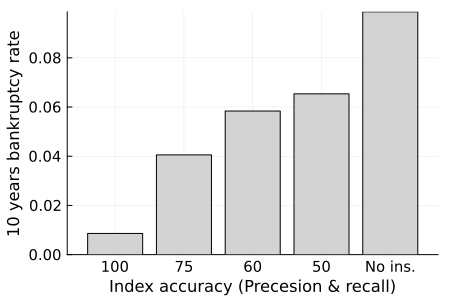

In [ ]:
rates = [b_rate_100.P10, b_rate_75.P10, b_rate_60.P10, b_rate_50.P10, b_rate_100.P10_no_I]

plt = Plots.bar(["100","75","60","50","No ins."], rates, 
            color = "lightgrey",
            xlab = "Index accuracy (Precesion & recall)",
            ylab = "10 years bankruptcy rate", label = "")

Plots.plot!(size = (450,300), legendfontsize = 10,
            tickfontsize = 10)
savefig("figures/bankruptcy_probabiltiy.png")
plt

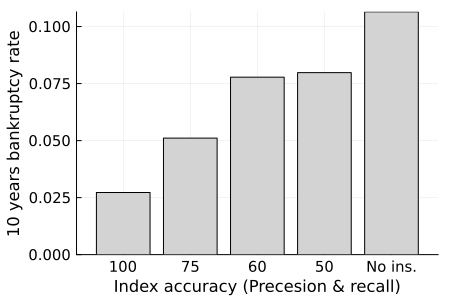

In [8]:
using Plots
rates = [b_rate_100_cv33.P10, b_rate_75_cv33.P10, b_rate_60_cv33.P10, b_rate_50_cv33.P10, b_rate_100.P10_no_I]

plt = Plots.bar(["100","75","60","50","No ins."], rates, 
            color = "lightgrey",
            xlab = "Index accuracy (Precesion & recall)",
            ylab = "10 years bankruptcy rate", label = "")

Plots.plot!(size = (450,300), legendfontsize = 10,
            tickfontsize = 10)
savefig("figures/bankruptcy_probabiltiy_cv33.png")
plt

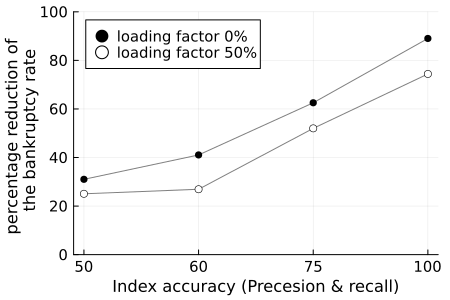

In [24]:
rates_pct_cv33 = reverse(100*[b_rate_100_cv33.P10, b_rate_75_cv33.P10, b_rate_60_cv33.P10, b_rate_50_cv33.P10]./b_rate_100.P10_no_I)
rates_pct = reverse(100*[b_rate_100.P10, b_rate_75.P10, b_rate_60.P10, b_rate_50.P10]./b_rate_100.P10_no_I)
x_axis = reverse(["100","75","60","50"])
plt = Plots.plot(x_axis, 100 .-rates_pct, color = "grey", label = "")
Plots.scatter!(x_axis, 100 .-rates_pct, color = "black", label = "loading factor 0%")
Plots.plot!(x_axis, 100 .-rates_pct_cv33, color = "grey", label = "")
Plots.scatter!(x_axis, 100 .-rates_pct_cv33, color = "white", label = "loading factor 50%")

Plots.plot!(size = (450,300), legendfontsize = 10,tickfontsize = 10, 
            xlab = "Index accuracy (Precesion & recall)",
            ylab = "percentage reduction of \n the bankruptcy rate",
            ylim = (0,100))

savefig("figures/change_in_bankruptcy_rate.png")
plt